# Section 3 – ELT with WebHDFS `InsecureClient`
**Big Data with Hadoop – Palmer Penguins**

This notebook (run on Windows) connects to the Hortonworks HDP Sandbox through WebHDFS, extracts `penguins.csv` from HDFS into Pandas, analyses and cleans it, and loads the cleaned file back to HDFS.

> Prerequisite: add `127.0.0.1  sandbox-hdp.hortonworks.com` to `C:\Windows\System32\drivers\etc\hosts` so WebHDFS redirects to the DataNode resolve.

In [1]:
# !pip install hdfs pandas matplotlib
import pandas as pd
import matplotlib.pyplot as plt
from hdfs import InsecureClient

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)

## 1. Connect to HDFS via WebHDFS

In [2]:
# WebHDFS endpoint of the NameNode.
#   HDP 2.6.x sandbox : http://sandbox-hdp.hortonworks.com:50070
#   HDP 3.x / Hadoop 3: http://<namenode-host>:9870
WEBHDFS_URL = 'http://localhost:9870'
client = InsecureClient(WEBHDFS_URL, user='maria_dev')

RAW_PATH   = '/user/maria_dev/datasets/penguins.csv'
CLEAN_DIR  = '/user/maria_dev/datasets/clean'
CLEAN_PATH = CLEAN_DIR + '/penguins_clean.csv'

print(client.list('/user/maria_dev/datasets'))
print(client.status(RAW_PATH))

['hive', 'penguins.csv']
{'accessTime': 1792672725963, 'blockSize': 134217728, 'childrenNum': 0, 'fileId': 16389, 'group': 'supergroup', 'length': 15241, 'modificationTime': 1792672726602, 'owner': 'maria_dev', 'pathSuffix': '', 'permission': '644', 'replication': 1, 'storagePolicy': 0, 'type': 'FILE'}


## 2. Extract – load penguins.csv into a Pandas DataFrame

In [3]:
with client.read(RAW_PATH, encoding='utf-8') as reader:
    df = pd.read_csv(reader, na_values=['NA', ''])

print('Shape:', df.shape)
df.head(10)

Shape: (344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,female,2007
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,male,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007


## 3. Analyse structure and missing values

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


In [5]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
species,344,3,Adelie,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
island,344,3,Biscoe,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bill_length_mm,342.0,NaN,NaN,NaN,43.92193,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,NaN,NaN,NaN,17.15117,1.974793,13.1,15.6,17.3,18.7,21.5
flipper_length_mm,342.0,NaN,NaN,NaN,200.915205,14.061714,172.0,190.0,197.0,213.0,231.0
body_mass_g,342.0,NaN,NaN,NaN,4201.754386,801.954536,2700.0,3550.0,4050.0,4750.0,6300.0
sex,333,2,male,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,344.0,NaN,NaN,NaN,2008.02907,0.818356,2007.0,2007.0,2008.0,2009.0,2009.0


In [6]:
missing = df.isna().sum().to_frame('missing')
missing['missing_%'] = (missing['missing'] / len(df) * 100).round(2)
print('Duplicate rows:', df.duplicated().sum())
missing

Duplicate rows: 0


,missing,missing_%
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20
year,0,0.00


In [7]:
df[df[['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g']].isna().all(axis=1)]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
271,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN,2009


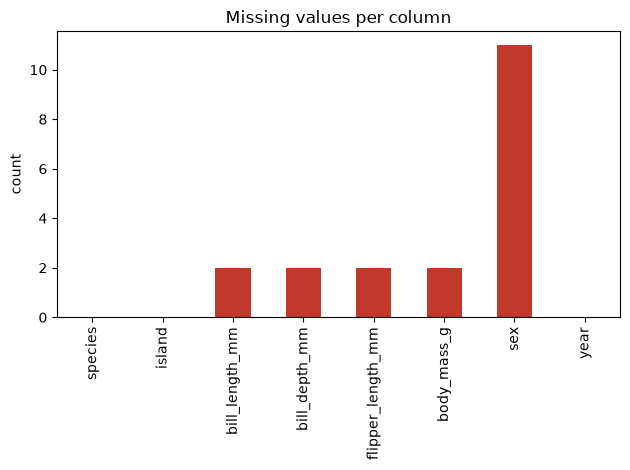

In [8]:
missing['missing'].plot(kind='bar', title='Missing values per column', color='#c0392b')
plt.ylabel('count'); plt.tight_layout(); plt.show()

## 4. Clean & preprocess
1. Remove duplicates.
2. Drop rows where **all** body measurements are missing (2 rows – no usable information).
3. Impute remaining numeric gaps with the **species median** (robust to outliers).
4. Normalise `sex` to lower case and impute missing values with the species mode.
5. Convert `body_mass_g` → `body_mass_kg`.

In [9]:
NUMERIC_COLS = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

clean = df.drop_duplicates().copy()
clean = clean.dropna(subset=NUMERIC_COLS, how='all')

for col in NUMERIC_COLS:
    clean[col] = clean.groupby('species')[col].transform(lambda s: s.fillna(s.median()))

clean['sex'] = clean['sex'].str.strip().str.lower()
clean['sex'] = clean.groupby('species')['sex'].transform(lambda s: s.fillna(s.mode().iloc[0]))

clean['body_mass_kg'] = (clean['body_mass_g'] / 1000.0).round(3)
clean = clean.drop(columns=['body_mass_g'])
clean['year'] = clean['year'].astype(int)
clean = clean[['species','island','bill_length_mm','bill_depth_mm',
               'flipper_length_mm','body_mass_kg','sex','year']].reset_index(drop=True)

print('Before:', df.shape, ' After:', clean.shape)
print(clean.isna().sum())
clean.head()

Before: (344, 8)  After: (342, 8)
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_kg         0
sex                  0
year                 0
dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_kg,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3.75,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3.80,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3.25,female,2007
3,Adelie,Torgersen,36.7,19.3,193.0,3.45,female,2007
4,Adelie,Torgersen,39.3,20.6,190.0,3.65,male,2007


In [10]:
clean.groupby('species')[['body_mass_kg','flipper_length_mm']].mean().round(3)

,body_mass_kg,flipper_length_mm
species,,
Adelie,3.701,189.954
Chinstrap,3.733,195.824
Gentoo,5.076,217.187


## 5. Load – upload cleaned dataset to HDFS

In [11]:
client.makedirs(CLEAN_DIR)
client.write(CLEAN_PATH, data=clean.to_csv(index=False), encoding='utf-8', overwrite=True)
print(client.list(CLEAN_DIR, status=True))

[('penguins_clean.csv', {'accessTime': 1792672910527, 'blockSize': 134217728, 'childrenNum': 0, 'fileId': 16394, 'group': 'supergroup', 'length': 15934, 'modificationTime': 1792672910680, 'owner': 'maria_dev', 'pathSuffix': 'penguins_clean.csv', 'permission': '644', 'replication': 1, 'storagePolicy': 0, 'type': 'FILE'})]


In [12]:
# Verify by reading it back
with client.read(CLEAN_PATH, encoding='utf-8') as r:
    check = pd.read_csv(r)
print(check.shape)
check.head()

(342, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_kg,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3.75,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3.80,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3.25,female,2007
3,Adelie,Torgersen,36.7,19.3,193.0,3.45,female,2007
4,Adelie,Torgersen,39.3,20.6,190.0,3.65,male,2007
